/tmp/ipython-input-7143029.py:34: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X.fillna(X.mean(), inplace=True)


Evaluation Metrics for PM2.5 Prediction:
MAE: 71.12
MSE: 5800.92
R2 Score: -21.66

Sample Prediction Table:
        Date  PM2.5 Actual  PM2.5 Predicted
8 2024-10-09            70            26.15
1 2024-10-02           102           200.38


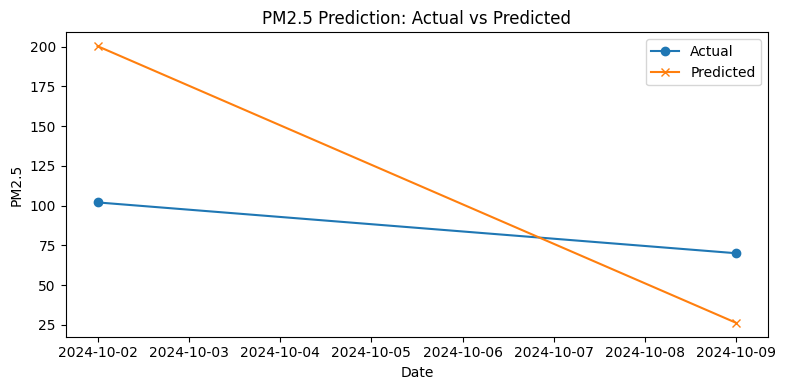


Predicted PM2.5 for new conditions: 136.62


In [1]:
# Air Quality Prediction in Hyderabad using Linear Regression

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

# 1. Sample Data Creation (replace with your full dataset for real project)
data = pd.DataFrame({
    'Date': pd.date_range(start='2024-10-01', periods=10, freq='D'),
    'Temperature': [32, 30, 29, 31, 33, 35, 34, 32, 31, 30],
    'Humidity': [45, 50, 48, 46, 44, 41, 42, 43, 46, 49],
    'WindSpeed': [8, 5, 6, 7, 9, 5, 7, 6, 8, 5],
    'PM2.5': [95, 102, 88, 75, 85, 110, 120, 105, 70, 90],
    'PM10': [120, 140, 135, 110, 115, 145, 150, 130, 108, 135],
    'NO': [45, 50, 48, 42, 47, 52, 55, 49, 43, 48],
    'CO': [1.4, 1.6, 1.3, 1.2, 1.5, 1.7, 1.8, 1.5, 1.1, 1.3],
    'SO': [17, 20, 16, 15, 18, 22, 23, 19, 13, 16],
    'Ozone': [25, 29, 27, 24, 28, 31, 33, 30, 22, 26]
})

# We will predict PM2.5 based on other features
target = 'PM2.5'
features = ['Temperature', 'Humidity', 'WindSpeed', 'PM10', 'NO', 'CO', 'SO', 'Ozone']

# 2. Preprocessing: Handle missing values and scale features
X = data[features]
y = data[target]

# For demonstration, fill any missing values (none in sample)
X.fillna(X.mean(), inplace=True)

# Feature scaling (optional but improves regression performance)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Train/Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42
)

# 4. Model Training
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# 5. Prediction
y_pred = lr_model.predict(X_test)

# 6. Evaluation
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Evaluation Metrics for PM2.5 Prediction:")
print(f"MAE: {mae:.2f}")
print(f"MSE: {mse:.2f}")
print(f"R2 Score: {r2:.2f}")

# 7. Results Table
result_df = pd.DataFrame({
    'Date': data.loc[y_test.index, 'Date'],
    'PM2.5 Actual': y_test.values,
    'PM2.5 Predicted': np.round(y_pred, 2)
})
print("\nSample Prediction Table:")
print(result_df)

# 8. Visualization (Actual vs Predicted)
plt.figure(figsize=(8, 4))
plt.plot(result_df['Date'], result_df['PM2.5 Actual'], marker='o', label='Actual')
plt.plot(result_df['Date'], result_df['PM2.5 Predicted'], marker='x', label='Predicted')
plt.title('PM2.5 Prediction: Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('PM2.5')
plt.legend()
plt.tight_layout()
plt.show()

# 9. Extension: Predict PM10 or add more models as needed

# 10. Demo: Predict for new sample data
new_sample = pd.DataFrame([{
    'Temperature': 31,
    'Humidity': 44,
    'WindSpeed': 7,
    'PM10': 120,
    'NO': 46,
    'CO': 1.5,
    'SO': 17,
    'Ozone': 27
}])
new_sample_scaled = scaler.transform(new_sample)
pred_pm25 = lr_model.predict(new_sample_scaled)[0]
print(f"\nPredicted PM2.5 for new conditions: {pred_pm25:.2f}")

